Datasets de entrada:
- Datos/Originales/DowJones/*_marketstack.csv  -> 26 CSV intradía (uno por empresa)
- Yahoo Finance (descarga con yfinance)         -> histórico diario 2016-2025 de las mismas 26
- Datos/Originales/Yahoo/yahoo_diario_<fecha>.csv -> descarga de Yahoo guardada (solo se descarga si no existe)

Dataset de salida:
   - Datos/Transformados/dowjones_diario_2016_2025.csv -> una vela diaria por empresa y día de
     mercado (2016-2025). El CSV manda; Yahoo imputa lo que el CSV no tiene o no es fiable y da el volumen.

In [1]:
import glob
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

from packages.bbva_graficos import BBVA, anotar_fuente, configurar_graficos, fechas_es, fmt_es, guardar_mpl, numeros_es

C:\Users\Personal\.conda\envs\BDA\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
def hhmm(minutos):
    if pd.isna(minutos) or minutos == "-":
        return "-"
    return f"{int(minutos) // 60:02d}:{int(minutos) % 60:02d}"

In [3]:
# Rutas y fechas
RUTA_ORIGINALES = "Datos/Originales/DowJones/*.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
FECHA_INICIO = "2016-01-01"
FECHA_FIN = "2026-01-01"    # exclusivo en yfinance (incluye hasta 2025-12-31)

# Horario de la sesión de Nueva York, en minutos desde medianoche
APERTURA = 9 * 60 + 30     # 09:30
CIERRE = 16 * 60           # 16:00
HORA_RESUMEN = 20 * 60     # 20:00 (fila resumen veraniega)
INICIO_MAXIMO = 10 * 60    # 10:00 como límite para considerar día completo
FIN_MINIMO = 15 * 60 + 30  # 15:30 como mínimo de cierre            

In [4]:
# Estilo común de los gráficos del reto (paleta BBVA)
configurar_graficos()
pd.set_option("display.width", 200)

# 1. Carga y unificación de los 26 CSV + primera exploración

In [5]:
archivos = sorted(glob.glob(RUTA_ORIGINALES))
df = pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
print(df.head(3).to_string())
print(df.dtypes)

     open    high      low  last   close  volume                      date symbol exchange
0  213.37  213.41  213.300   NaN  213.30     NaN  2018-08-16T21:30:00+0000   AAPL     IEXG
1  213.28  213.41  213.160   NaN  213.30     NaN  2018-08-16T21:00:00+0000   AAPL     IEXG
2  213.43  213.43  212.985   NaN  213.28     NaN  2018-08-16T20:30:00+0000   AAPL     IEXG
open        float64
high        float64
low         float64
last        float64
close       float64
volume      float64
date            str
symbol          str
exchange        str
dtype: object


In [6]:
df["date"] = pd.to_datetime(df["date"])         
print("date ->", df["date"].dtype)

empresas = sorted(df["symbol"].unique())
print(f"\n{len(archivos)} ficheros | {len(empresas)} empresas | {len(df):,} filas")
print(empresas)
print("exchange:", df["exchange"].value_counts().to_dict())

date -> datetime64[us, UTC]

26 ficheros | 26 empresas | 2,744,418 filas
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']


exchange: {'IEXG': 2744418}


In [7]:
# Missings: número y porcentaje sobre el total de filas
print(pd.DataFrame({"nulos": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)}))

print("Duplicados exactos:", df.duplicated().sum(), "| Duplicados symbol+date:", df.duplicated(subset=["symbol", "date"]).sum())

print("Precios <= 0:", int((df[["open", "high", "low", "close", "last"]] <= 0).sum().sum()),
      "| Volumen negativo:", int((df["volume"] < 0).sum()))

           nulos    pct
open           0   0.00
high           0   0.00
low            0   0.00
last      849956  30.97
close     611651  22.29
volume    847408  30.88
date           0   0.00
symbol         0   0.00
exchange       0   0.00


Duplicados exactos: 0 | Duplicados symbol+date: 0
Precios <= 0: 0 | Volumen negativo: 0


In [8]:
paso = df.groupby("symbol", sort=False)["date"].diff()
bloques = (paso > pd.Timedelta(0)).groupby(df["symbol"]).sum()
print(f"\nFilas cuya fecha es anterior a la de la fila previa: {(paso < pd.Timedelta(0)).mean():.1%}"
      f" | saltos hacia delante (bloques) por fichero: {bloques.min()}-{bloques.max()}")
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

print(df.groupby("symbol")["date"].agg(["min", "max", "count"]))


Filas cuya fecha es anterior a la de la fila previa: 99.9% | saltos hacia delante (bloques) por fichero: 25-136


                             min                       max   count
symbol                                                            
AAPL   2018-06-06 17:30:00+00:00 2021-07-01 00:00:00+00:00   48723
AMGN   2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00   25296
AXP    2020-05-29 15:30:59+00:00 2021-07-01 00:00:00+00:00   95650
BA     2020-05-29 15:35:51+00:00 2021-07-01 00:00:00+00:00  101436
CAT    2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  122364
CRM    2020-05-29 15:31:30+00:00 2021-07-01 00:00:00+00:00  108823
CSCO   2020-05-29 15:31:26+00:00 2021-07-01 00:00:00+00:00  108585
CVX    2020-05-29 15:31:23+00:00 2021-07-01 00:00:00+00:00  108876
DIS    2020-05-29 15:35:00+00:00 2021-07-01 00:00:00+00:00  109393
DOW    2020-05-29 15:35:56+00:00 2021-07-01 00:00:00+00:00  106437
GS     2018-06-11 17:30:00+00:00 2021-07-01 00:00:00+00:00  133145
HD     2020-05-29 17:55:51+00:00 2021-07-01 00:00:00+00:00  105219
IBM    2020-05-29 17:56:29+00:00 2021-07-01 00:00:00+00:00  10

Los ficheros vienen por bloques y en orden descendente: hay que ordenar antes de quedarnos con el primer o el último valor de cada día.

# 2. Hora de Nueva York: la sesión y los días de mercado se definen allí, no en UTC

In [9]:
df["hora_ny"] = df["date"].dt.tz_convert("America/New_York")
df["dia_ny"] = df["hora_ny"].dt.tz_localize(None).dt.normalize()
df["minuto_ny"] = df["hora_ny"].dt.hour * 60 + df["hora_ny"].dt.minute

# Diferencia horaria entre UTC y Nueva York en cada fila, en minutos: 240 en verano (EDT), 300 en invierno (EST)
df["desfase_utc"] = ((df["date"].dt.tz_localize(None) - df["hora_ny"].dt.tz_localize(None))
                     .dt.total_seconds() // 60).astype(int)

dia_utc = df["date"].dt.tz_localize(None).dt.normalize()

print("Filas que caen en fin de semana agrupando por día UTC:", int((dia_utc.dt.dayofweek >= 5).sum()))
print("Filas que caen en fin de semana agrupando por día NY: ", int((df["dia_ny"].dt.dayofweek >= 5).sum()))
print("Desfase UTC - NY (minutos):", df["desfase_utc"].value_counts().to_dict())

Filas que caen en fin de semana agrupando por día UTC: 13702
Filas que caen en fin de semana agrupando por día NY:  0
Desfase UTC - NY (minutos): {240: 1932754, 300: 811664}


# 3. Qué significa cada columna: ¿por qué el 27,7 % de las filas tiene close fuera de [low, high]?

In [10]:
fuera_rango = (df["close"] > df["high"]) | (df["close"] < df["low"])

print(f"Filas con close fuera de [low, high]: {fuera_rango.sum():,} de {len(df):,} ({fuera_rango.mean():.1%})")
print(f"  de ellas, filas que tienen last: {df.loc[fuera_rango, 'last'].notna().mean():.1%}")

Filas con close fuera de [low, high]: 761,432 de 2,744,418 (27.7%)
  de ellas, filas que tienen last: 99.9%


In [11]:
# Día con más rango de CRM: si close está mal, ahí se nota más
crm = df[df["symbol"] == "CRM"]
rango_dia = crm.groupby("dia_ny")["high"].max() - crm.groupby("dia_ny")["low"].min()
dia_crm = rango_dia.idxmax()
dia_crm_ant = crm.loc[crm["dia_ny"] < dia_crm, "dia_ny"].max()

columnas_ver = ["hora_ny", "open", "high", "low", "last", "close", "volume"]
print(f"Día con más rango en CRM: {dia_crm.date()} (una fila de cada 60)")
print(crm.loc[crm["dia_ny"] == dia_crm, columnas_ver].iloc[::60].to_string())

# Tarde del día anterior: de ahí sale el valor fijo de close
crm_25 = crm[(crm["dia_ny"] == dia_crm_ant) & (crm["minuto_ny"] >= 15 * 60 + 55)]
print(f"\nCRM {dia_crm_ant.date()} desde las 15:55:")
print(crm_25[["hora_ny", "last", "close", "volume"]].to_string())

Día con más rango en CRM: 2020-08-26 (una fila de cada 60)
                         hora_ny    open    high     low     last   close     volume
410616 2020-08-26 08:52:00-04:00  249.29  249.29  246.78  246.780  216.05     4599.0
410676 2020-08-26 10:32:00-04:00  249.29  276.14  246.78  272.325  216.05   580805.0
410736 2020-08-26 11:47:00-04:00  249.29  277.79  246.78  271.130  216.05  1171892.0
410796 2020-08-26 13:09:00-04:00  249.29  277.79  246.78  274.185  216.05  1401530.0
410856 2020-08-26 14:25:00-04:00  249.29  277.79  246.78  271.675  216.05  1596052.0
410916 2020-08-26 15:42:00-04:00  249.29  277.79  246.78  269.630  216.05  1738652.0

CRM 2020-08-25 desde las 15:55:
                         hora_ny     last   close      volume
410603 2020-08-25 15:56:00-04:00  216.370  208.46    465697.0
410604 2020-08-25 15:57:00-04:00  216.190  208.46    469002.0
410605 2020-08-25 15:58:00-04:00  216.120  208.46    472393.0
410606 2020-08-25 15:59:00-04:00  216.100  208.46    477093.0
410

En las filas con last, close no es el precio del minuto sino el cierre oficial del día anterior; por eso cae fuera de [low, high].

En esas filas, open es la apertura del día, high/low son los extremos acumulados y volume es acumulado.

Después de las 16:00 siguen llegando precios (after-hours), así que el último last antes de la fila resumen no vale como cierre; la última fila del día (20:00) es un resumen con el cierre oficial.

In [12]:
# ¿El volumen es acumulado en todo el dataset, no solo en el ejemplo?
variacion = df.dropna(subset=["volume"]).groupby(["symbol", "dia_ny"])["volume"].diff().dropna()
print(f"\nMinutos consecutivos en los que el volumen crece o se mantiene: {(variacion >= 0).mean():.2%}")

# En las filas sin last, close sí cambia dentro del día (es el cierre de cada barra)
aapl_sin_last = df[(df["symbol"] == "AAPL") & df["last"].isna() & (df["dia_ny"] < "2020-05-29")]
rango_aapl = aapl_sin_last.groupby("dia_ny")["high"].max() - aapl_sin_last.groupby("dia_ny")["low"].min()
barras_aapl = aapl_sin_last[aapl_sin_last["dia_ny"] == rango_aapl.idxmax()]
print(f"AAPL {rango_aapl.idxmax().date()} (sin last): {barras_aapl['close'].nunique()} valores distintos de close "
      f"en {len(barras_aapl)} barras")


Minutos consecutivos en los que el volumen crece o se mantiene: 99.98%
AAPL 2020-03-13 (sin last): 37 valores distintos de close en 79 barras


Guardado: Graficos\limpieza_crm_last_vs_close.png


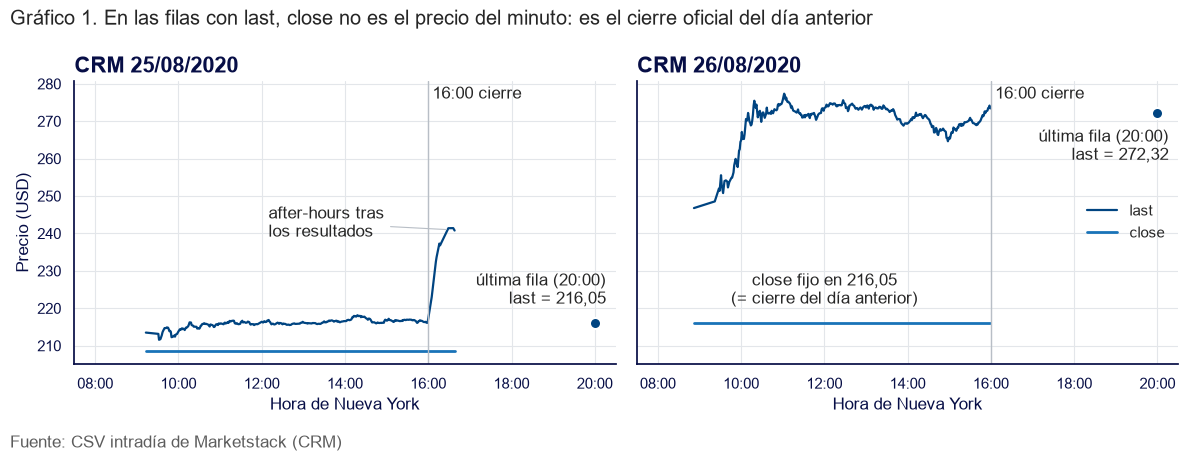

In [13]:
# Gráfico: los dos días de CRM. last sigue al precio; close se queda en el cierre del día anterior
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
# La etiqueta de la última fila va encima o debajo del punto según dónde queda hueco en cada panel
for ax, dia, dy in zip(ejes, [dia_crm_ant, dia_crm], [14, -34]):
    d = crm[crm["dia_ny"] == dia]
    intradia, final = d[d["minuto_ny"] < HORA_RESUMEN], d[d["minuto_ny"] >= HORA_RESUMEN]
    x = intradia["minuto_ny"] / 60
    ax.plot(x, intradia["last"], color=BBVA["principal"], lw=1.6, label="last")
    ax.plot(x, intradia["close"], color=BBVA["medio"], lw=2, label="close")
    if len(final):
        ax.plot(final["minuto_ny"] / 60, final["last"], "o", ms=8, color=BBVA["principal"], mec=BBVA["blanco"], mew=1.5)
        ax.annotate(f"última fila (20:00)\nlast = {fmt_es(final['last'].iloc[0], 2)}", (20, final["last"].iloc[0]),
                    xytext=(8, dy), textcoords="offset points", ha="right")
    ax.axvline(16, color=BBVA["gris_dato"], lw=1)
    ax.text(16.1, 0.98, "16:00 cierre", transform=ax.get_xaxis_transform(), va="top")
    ax.set_title(f"CRM {dia:%d/%m/%Y}")
    ax.set_xticks(range(8, 21, 2), [f"{h:02d}:00" for h in range(8, 21, 2)])
    ax.set_xlim(7.5, 20.5)
    ax.set_xlabel("Hora de Nueva York")
ejes[0].set_ylabel("Precio (USD)")
numeros_es(ejes[0].yaxis)
ejes[0].annotate("after-hours tras\nlos resultados", (16.5, 241), xytext=(-130, -5), textcoords="offset points",
                 arrowprops=dict(arrowstyle="-", color=BBVA["gris_dato"], lw=0.8))
close_fijo = crm.loc[crm["dia_ny"] == dia_crm, "close"].iloc[0]
ejes[1].annotate(f"close fijo en {fmt_es(close_fijo, 2)}\n(= cierre del día anterior)", (12, close_fijo), xytext=(0, 14),
                 textcoords="offset points", ha="center")
ejes[1].legend(loc="center right")
fig.suptitle("Gráfico 1. En las filas con last, close no es el precio del minuto: es el cierre oficial del día anterior", x=0.01, ha="left")
plt.tight_layout()
anotar_fuente(fig, "CSV intradía de Marketstack (CRM)")
guardar_mpl(fig, "limpieza_crm_last_vs_close")
plt.show()

# 4. Filas con last y filas sin last: dos flujos de datos distintos mezclados en el CSV

In [14]:
# Tipo de cada día: solo filas con last, solo sin last o mixto
df["tiene_last"] = df["last"].notna()
por_dia = df.groupby(["symbol", "dia_ny"])["tiene_last"].agg(["all", "any"])
por_dia["tipo"] = np.select([por_dia["all"], por_dia["any"]], ["solo con last", "mixto"], "solo sin last")
print(por_dia["tipo"].value_counts().to_string())
print(por_dia.reset_index().groupby("tipo")["dia_ny"].agg(["min", "max"]).to_string())

tipo
solo con last    4212
solo sin last    3272
mixto            2693
                     min        max
tipo                               
mixto         2020-05-29 2021-06-30
solo con last 2020-05-29 2021-02-24
solo sin last 2018-06-06 2021-03-31


In [15]:
# Miramos el primer día mixto de AMGN, alrededor de las 14:00 y de las 18:00
dia_amgn = por_dia.loc["AMGN"].query("tipo == 'mixto'").index.min()
amgn = df[(df["symbol"] == "AMGN") & (df["dia_ny"] == dia_amgn)]

print(f"\nAMGN {dia_amgn.date()}: filas CON last entre las 14:00 y las 14:20")
print(amgn.loc[amgn["tiene_last"] & amgn["minuto_ny"].between(14 * 60, 14 * 60 + 20), columnas_ver].to_string())

print(f"AMGN {dia_amgn.date()}: filas SIN last entre las 18:00 y las 18:20")
print(amgn.loc[~amgn["tiene_last"] & amgn["minuto_ny"].between(18 * 60, 18 * 60 + 20), columnas_ver].to_string())

barras = df[~df["tiene_last"]]
horario = barras.groupby(["symbol", "dia_ny"]).agg(primera=("minuto_ny", "min"), ultima=("minuto_ny", "max"),
                                                   desfase=("desfase_utc", "first"))
horario_tipico = horario.groupby("desfase")[["primera", "ultima"]].agg(lambda s: hhmm(s.mode().iloc[0]))
horario_tipico.index = horario_tipico.index.map({240: "verano (UTC-4)", 300: "invierno (UTC-5)"})
print("\nHora (NY) más frecuente de la primera y la última barra de cada día:")
print(horario_tipico.to_string())


AMGN 2020-06-15: filas CON last entre las 14:00 y las 14:20
                        hora_ny     open     high     low     last  close   volume
49147 2020-06-15 14:00:00-04:00  215.465  218.185  213.93  218.185  217.9  38496.0
49148 2020-06-15 14:05:00-04:00  215.465  219.540  213.93  219.540  217.9  45687.0
49150 2020-06-15 14:15:00-04:00  215.465  219.960  213.93  219.960  217.9  45832.0
49151 2020-06-15 14:20:00-04:00  215.465  220.525  213.93  220.525  217.9  46334.0
AMGN 2020-06-15: filas SIN last entre las 18:00 y las 18:20
                        hora_ny     open     high      low  last    close  volume
49195 2020-06-15 18:00:00-04:00  218.185  218.185  218.185   NaN  218.185     NaN
49196 2020-06-15 18:05:00-04:00  219.540  219.540  219.540   NaN  219.540     NaN
49197 2020-06-15 18:10:00-04:00  219.540  219.540  219.540   NaN  219.540     NaN
49198 2020-06-15 18:15:00-04:00  219.960  219.960  219.960   NaN  219.960     NaN
49199 2020-06-15 18:20:00-04:00  220.525  220.955  220


Hora (NY) más frecuente de la primera y la última barra de cada día:
                 primera ultima
desfase                        
verano (UTC-4)     13:30  20:00
invierno (UTC-5)   14:30  21:00


Las filas sin last son barras de 1 a 30 minutos, casi siempre sin volumen, con la hora desplazada 4 h en verano y 5 h en invierno.

In [16]:
# Corrección: a las barras se les resta el desfase; las filas con last ya vienen en su hora.
df["minuto_real"] = np.where(df["tiene_last"], df["minuto_ny"], df["minuto_ny"] - df["desfase_utc"])
# Filas sin last que, ya corregidas, quedan fuera de la sesión (no afectan)

raras = ~df["tiene_last"] & ~df["minuto_real"].between(APERTURA, CIERRE)
print(f"Filas sin last que quedan fuera de la sesión tras corregir: {raras.sum()} | hora NY: "
      f"{df.loc[raras, 'hora_ny'].dt.hour.value_counts().sort_index().to_dict()} | con volumen: {df.loc[raras, 'volume'].notna().sum()}")

Filas sin last que quedan fuera de la sesión tras corregir: 259 | hora NY: {9: 158, 10: 96, 11: 5} | con volumen: 259


Guardado: Graficos\limpieza_amgn_desfase_barras.png


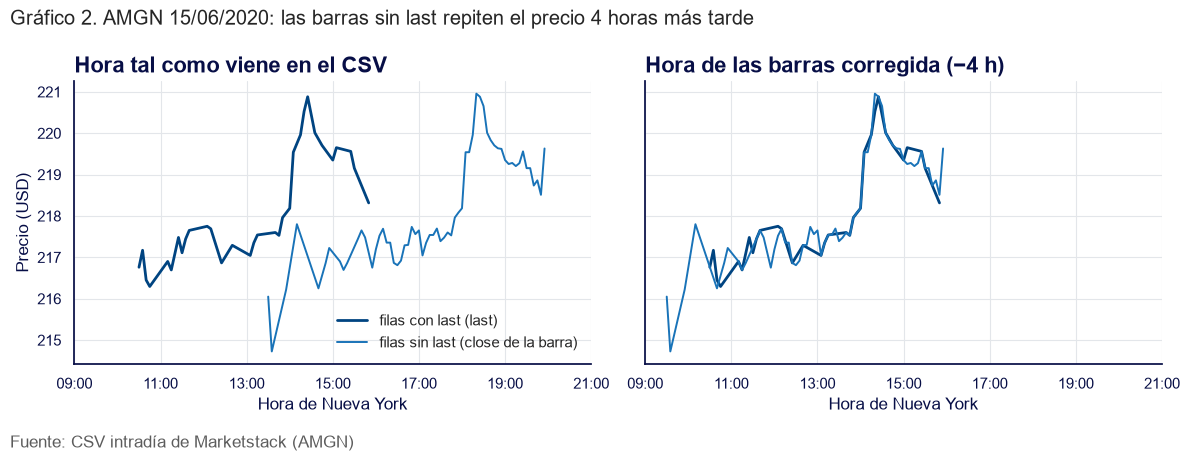

In [17]:
# Gráfico: el mismo día de AMGN antes y después de corregir la hora de las barras
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
con_last = amgn[amgn["tiene_last"] & (amgn["minuto_ny"] < HORA_RESUMEN)]
sin_last = amgn[~amgn["tiene_last"]]
for ax, corregida in zip(ejes, [False, True]):
    x_barras = (sin_last["minuto_ny"] - (sin_last["desfase_utc"] if corregida else 0)) / 60
    ax.plot(con_last["minuto_ny"] / 60, con_last["last"], color=BBVA["principal"], lw=2, label="filas con last (last)")
    ax.plot(x_barras, sin_last["close"], color=BBVA["medio"], lw=1.4, label="filas sin last (close de la barra)")
    ax.set_title("Hora de las barras corregida (−4 h)" if corregida else "Hora tal como viene en el CSV")
    ax.set_xticks(range(9, 22, 2), [f"{h:02d}:00" for h in range(9, 22, 2)])
    ax.set_xlim(9, 21)
    ax.set_xlabel("Hora de Nueva York")
ejes[0].set_ylabel("Precio (USD)")
numeros_es(ejes[0].yaxis)
ejes[0].legend(loc="lower right")
fig.suptitle(f"Gráfico 2. AMGN {dia_amgn:%d/%m/%Y}: las barras sin last repiten el precio 4 horas más tarde", x=0.01, ha="left")
plt.tight_layout()
anotar_fuente(fig, "CSV intradía de Marketstack (AMGN)")
guardar_mpl(fig, "limpieza_amgn_desfase_barras")
plt.show()

# 5. Yahoo Finance (2016-2025) para las mismas 26 empresas: se descarga una vez y se guarda

In [18]:
# Yahoo se descarga una sola vez y se guarda con su fecha en Datos/Originales/Yahoo/; si ya existe, se lee
CARPETA_YAHOO = "Datos/Originales/Yahoo"
guardadas = sorted(glob.glob(f"{CARPETA_YAHOO}/yahoo_diario_*.csv"))
fallidos = []
if guardadas:
    ruta_yahoo = guardadas[-1]
    # round_trip: recupera cada decimal exactamente como se guardó
    yahoo = pd.read_csv(ruta_yahoo, parse_dates=["date"], float_precision="round_trip")
    print("Yahoo leído de", ruta_yahoo)
else:
    partes = []
    for ticker in empresas:
        try:
            hist = yf.Ticker(ticker).history(start=FECHA_INICIO, end=FECHA_FIN, auto_adjust=False)
            if hist.empty:
                fallidos.append(ticker)
                continue
            # Adj Close solo se usa en el gráfico del split; Stock Splits incluye los spin-offs
            hist = hist.reset_index()[["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume", "Stock Splits"]]
            hist.columns = ["date", "open", "high", "low", "close", "adj_close", "volume", "split"]
            hist["date"] = pd.to_datetime(hist["date"]).dt.tz_localize(None).dt.normalize()
            hist["symbol"] = ticker
            partes.append(hist)
        except Exception as error:
            fallidos.append(ticker)
            print(f"{ticker}: falló la descarga -> {error}")
    yahoo = pd.concat(partes, ignore_index=True)
    os.makedirs(CARPETA_YAHOO, exist_ok=True)
    ruta_yahoo = f"{CARPETA_YAHOO}/yahoo_diario_{pd.Timestamp.today():%Y-%m-%d}.csv"
    yahoo.to_csv(ruta_yahoo, index=False)
    print("Yahoo descargado y guardado en", ruta_yahoo)

# Eventos de split (y spin-offs, que Yahoo registra como split) dentro de la ventana
splits = {t: g.loc[g["split"] != 0].set_index("date")["split"] for t, g in yahoo.groupby("symbol")}
print("Descargadas:", yahoo["symbol"].nunique(), "de", len(empresas), "| Fallidas:", fallidos)
print(yahoo.groupby("symbol")["date"].agg(["min", "max", "count"]))

Yahoo leído de Datos/Originales/Yahoo\yahoo_diario_2026-11-03.csv
Descargadas: 26 de 26 | Fallidas: []
              min        max  count
symbol                             
AAPL   2016-01-04 2025-12-31   2514
AMGN   2016-01-04 2025-12-31   2514
AXP    2016-01-04 2025-12-31   2514
BA     2016-01-04 2025-12-31   2514
CAT    2016-01-04 2025-12-31   2514
CRM    2016-01-04 2025-12-31   2514
CSCO   2016-01-04 2025-12-31   2514
CVX    2016-01-04 2025-12-31   2514
DIS    2016-01-04 2025-12-31   2514
DOW    2019-03-20 2025-12-31   1707
GS     2016-01-04 2025-12-31   2514
HD     2016-01-04 2025-12-31   2514
IBM    2016-01-04 2025-12-31   2514
INTC   2016-01-04 2025-12-31   2514
JNJ    2016-01-04 2025-12-31   2514
JPM    2016-01-04 2025-12-31   2514
KO     2016-01-04 2025-12-31   2514
MCD    2016-01-04 2025-12-31   2514
MMM    2016-01-04 2025-12-31   2514
MRK    2016-01-04 2025-12-31   2514
MSFT   2016-01-04 2025-12-31   2514
NKE    2016-01-04 2025-12-31   2514
PG     2016-01-04 2025-12-31   25

In [19]:
# Calidad de Yahoo, con los mismos controles que al CSV
print("Nulos:", int(yahoo.isna().sum().sum()), "| Duplicados symbol+date:", int(yahoo.duplicated(["symbol", "date"]).sum()),
      "| Precios <= 0:", int((yahoo[["open", "high", "low", "close"]] <= 0).sum().sum()),
      "| Volumen 0:", int((yahoo["volume"] == 0).sum()),
      "| Velas incoherentes:", int(((yahoo["high"] < yahoo[["open", "close"]].max(axis=1))
                                    | (yahoo["low"] > yahoo[["open", "close"]].min(axis=1))).sum()))

print("Días de mercado por año (AAPL):", yahoo[yahoo["symbol"] == "AAPL"].groupby(yahoo["date"].dt.year).size().to_dict())
print("¿Hay datos el 05/12/2018 o el 09/01/2025 (bolsa cerrada)?", bool(yahoo["date"].isin(["2018-12-05", "2025-01-09"]).any()))

Nulos: 0 | Duplicados symbol+date: 0 | Precios <= 0: 0 | Volumen 0: 0 | Velas incoherentes: 0
Días de mercado por año (AAPL): {2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}
¿Hay datos el 05/12/2018 o el 09/01/2025 (bolsa cerrada)? False


Yahoo sale limpio y sigue el calendario de la bolsa de Nueva York, con sus cierres extraordinarios: lo usamos como calendario, como referencia, para imputar y como fuente del volumen.

In [20]:
dow = yahoo[yahoo["symbol"] == "DOW"]
print(f"DOW: volumen mediano del 20/03 al 29/03/2019 {dow.loc[dow['date'] <= '2019-03-29', 'volume'].median():,.0f}"
      f" | en abril de 2019 {dow.loc[dow['date'].between('2019-04-01', '2019-04-30'), 'volume'].median():,.0f}")

DOW: volumen mediano del 20/03 al 29/03/2019 1,304,700 | en abril de 2019 6,681,600


DOW cotiza desde el 20/03/2019 (escisión de DowDuPont): antes no hay datos que imputar.

# 6. La fila resumen del final del día y el close del día siguiente: el cierre oficial

In [21]:
calendario = yahoo[["symbol", "date"]].sort_values(["symbol", "date"]).reset_index(drop=True)
calendario["dia_anterior"] = calendario.groupby("symbol")["date"].shift()

df["es_resumen"] = df["tiene_last"] & (df["minuto_ny"] >= HORA_RESUMEN)
resumen = df[df["es_resumen"]].drop(columns="date").rename(columns={"dia_ny": "date"})
es_ultima = df["date"] == df.groupby(["symbol", "dia_ny"])["date"].transform("max")

print("Filas con last a partir de las 20:00:", len(resumen), "| hora NY:",
      resumen["hora_ny"].dt.strftime("%H:%M").value_counts().to_dict())
print("¿Es siempre la última fila de su día?", bool(es_ultima[df["es_resumen"]].all()),
      "| ¿Como mucho una por día?", bool(resumen.groupby(["symbol", "date"]).size().max() == 1))

# El close de las filas con last es el cierre oficial del día anterior: se asigna a ese día
cierre_oficial = (
    df[df["tiene_last"] & ~df["es_resumen"]]
    .groupby(["symbol", "dia_ny"])["close"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
    .rename("cierre_oficial").reset_index().rename(columns={"dia_ny": "date"})
    .merge(calendario, on=["symbol", "date"])
    .dropna(subset=["dia_anterior", "cierre_oficial"])
    [["symbol", "dia_anterior", "cierre_oficial"]].rename(columns={"dia_anterior": "date"})
)

comp = resumen[["symbol", "date", "last"]].merge(cierre_oficial, on=["symbol", "date"])
coincide = (comp["last"] - comp["cierre_oficial"]).abs() < 0.005
print(f"Filas resumen con día siguiente en el CSV: {len(comp)} | last == close del día siguiente: {coincide.mean():.2%}")

# Donde no coinciden, ¿cuál es el bueno? Lo miramos contra Yahoo (son empresas sin splits en esas fechas)
distintos = comp[~coincide].merge(yahoo[["symbol", "date", "close"]], on=["symbol", "date"])
print(f"No coinciden: {len(distintos)} {distintos['symbol'].value_counts().to_dict()} | meses: "
      f"{distintos['date'].dt.strftime('%m/%Y').unique().tolist()}")
print(distintos.head(5).to_string())
print(f"  igual a Yahoo: el last del resumen en {(distintos['last'] - distintos['close']).abs().lt(0.005).sum()} casos,"
      f" el close del día siguiente en {(distintos['cierre_oficial'] - distintos['close']).abs().lt(0.005).sum()}")

Filas con last a partir de las 20:00: 4692 | hora NY: {'20:00': 2598, '21:00': 2094}
¿Es siempre la última fila de su día? True | ¿Como mucho una por día? True


Filas resumen con día siguiente en el CSV: 4649 | last == close del día siguiente: 99.44%
No coinciden: 26 {'DIS': 12, 'CVX': 9, 'AXP': 5} | meses: ['07/2020']
  symbol       date   last  cierre_oficial      close
0    AXP 2020-07-06  96.57           96.58  96.580002
1    AXP 2020-07-08  92.89           92.90  92.900002
2    AXP 2020-07-09  90.60           90.57  90.570000
3    AXP 2020-07-20  93.97           94.00  94.000000
4    AXP 2020-07-21  96.32           96.33  96.330002
  igual a Yahoo: el last del resumen en 0 casos, el close del día siguiente en 26


La última fila con last de cada día (20:00 en verano, 21:00 en invierno) es un resumen: su last es el cierre oficial, el mismo que repite close al día siguiente.

Cuando no coinciden, el que cuadra con Yahoo es el close del día siguiente: se usa primero y, si falta, el last del resumen.

In [22]:
# ¿La fila resumen es siempre una vela normal? Comprobamos su coherencia (high >= open, cierre; low <= open, cierre)
incoherente = (resumen["high"] < resumen[["open", "last"]].max(axis=1)) | (resumen["low"] > resumen[["open", "last"]].min(axis=1))
degenerada = (resumen["open"] == resumen["high"]) & (resumen["high"] == resumen["low"])
print(f"\nFilas resumen incoherentes: {incoherente.sum()} (todas con open = high = low: {bool(degenerada[incoherente].all())})"
      f" | filas resumen con open = high = low: {degenerada.sum()}")
print(resumen.loc[degenerada, ["symbol", "date", "open", "high", "low", "last", "volume"]].to_string())
# Las incoherentes tienen open = high = low (vela rota): en esos días open/high/low salen de la sesión

# Volumen de la fila resumen (total del mercado) frente al acumulado de las filas anteriores (solo IEX)
vol_antes = df[df["tiene_last"] & ~df["es_resumen"]].groupby(["symbol", "dia_ny"])["volume"].max()
vol_antes.index = vol_antes.index.set_names(["symbol", "date"])
print(f"Volumen de la fila resumen / volumen acumulado antes de ella: mediana "
      f"{(resumen.set_index(['symbol', 'date'])['volume'] / vol_antes).median():.1f}")


Filas resumen incoherentes: 8 (todas con open = high = low: True) | filas resumen con open = high = low: 9
        symbol       date     open     high      low    last      volume
21489     AAPL 2020-05-29  318.990  318.990  318.990  317.94  38399532.0
21571     AAPL 2020-06-01  321.775  321.775  321.775  321.85  20254653.0
21880     AAPL 2020-06-04  322.320  322.320  322.320  322.32  21316854.0
22005     AAPL 2020-06-05  331.480  331.480  331.480  331.50  33592989.0
1306767   INTC 2020-05-29   63.035   63.035   63.035   62.93  33395738.0
1307159   INTC 2020-06-01   61.840   61.840   61.840   61.86  14329044.0
1308703   INTC 2020-06-04   62.960   62.960   62.960   62.97  21578600.0
1309376   INTC 2020-06-05   64.275   64.275   64.275   64.34  26635504.0
1309936   INTC 2020-06-08   63.665   63.665   63.665   63.67  21175383.0


Volumen de la fila resumen / volumen acumulado antes de ella: mediana 33.3


In [23]:
# ¿Qué días tienen fila resumen? % de días (empresa-día) de cada mes con cada tipo de fila
tipo_dia = df.groupby(["symbol", "dia_ny"]).agg(barras=("tiene_last", lambda s: (~s).any()),
                                                con_last=("tiene_last", "any"), resumen=("es_resumen", "any"))
pct_mes = tipo_dia.groupby(tipo_dia.index.get_level_values("dia_ny").to_period("M")).mean() * 100
print("% de días (empresa-día) de cada mes con cada tipo de fila (antes de mayo de 2020: 100 % barras):")
print(pct_mes.loc["2020-05":].round(1).to_string())

# La fila resumen aparece de junio de 2020 a febrero de 2021 y desaparece desde marzo de 2021

% de días (empresa-día) de cada mes con cada tipo de fila (antes de mayo de 2020: 100 % barras):
         barras  con_last  resumen
dia_ny                            
2020-05    88.1      15.4     15.4
2020-06    25.3      91.1     83.9
2020-07     6.8     100.0     96.7
2020-08    12.3     100.0     97.4
2020-09     9.0     100.0     92.7
2020-10    37.4      92.5     80.4
2020-11     5.8     100.0     99.8
2020-12     7.2     100.0     99.7
2021-01     1.4     100.0     99.6
2021-02    11.7     100.0     99.0
2021-03   100.0      84.3     18.7
2021-04   100.0     100.0      0.9
2021-05   100.0     100.0      0.2
2021-06   100.0     100.0      0.0


# 7. Vela diaria del CSV

- close: cierre oficial -> el close del día siguiente y, si no hay, el last de la fila resumen; si no hay
ninguno de los dos, el último precio de la sesión (last en las filas con last, close en las barras)
- open/high/low: los de la fila resumen; si no hay resumen (o es una vela rota), salen de la sesión real
(09:30-16:00, barras con la hora corregida)
- volumen: el de la fila resumen y, si no hay, el acumulado de la sesión (solo IEX). Solo se usa, en los días
con fila resumen, para comprobar el ajuste por splits (sección 8); el volumen del dataset final sale de Yahoo
- día incompleto (open/high/low de una sesión cortada, o cierre tomado antes de las 15:30) -> se marca

In [24]:
vela_resumen = resumen.groupby(["symbol", "date"]).agg(
    open_res=("open", "last"), high_res=("high", "last"), low_res=("low", "last"),
    close_res=("last", "last"), volume_res=("volume", "last"))

sesion = df[df["minuto_real"].between(APERTURA, CIERRE)].sort_values(["symbol", "dia_ny", "minuto_real"])
sesion = sesion.assign(precio=np.where(sesion["tiene_last"], sesion["last"], sesion["close"]))
con_precio = sesion.dropna(subset=["precio"]).groupby(["symbol", "dia_ny"])
g = sesion.groupby(["symbol", "dia_ny"])
vela_sesion = pd.DataFrame({
    "open": g["open"].first(), "high": g["high"].max(), "low": g["low"].min(),
    "volume": g["volume"].max(),                  # acumulado -> el máximo es el total
    "inicio": g["minuto_real"].min(), "fin": g["minuto_real"].max(),
    "precio_sesion": con_precio["precio"].last(), "hora_precio": con_precio["minuto_real"].last(),
})
vela_sesion.index = vela_sesion.index.set_names(["symbol", "date"])

In [25]:
diario = (
    df.groupby(["symbol", "dia_ny"]).size().rename("filas").rename_axis(["symbol", "date"]).to_frame()
    .join(vela_resumen).join(vela_sesion)
    .reset_index()
    .merge(cierre_oficial, on=["symbol", "date"], how="left")
)
diario["tiene_resumen"] = diario["close_res"].notna()
ohl_resumen = diario["tiene_resumen"] & ~((diario["open_res"] == diario["high_res"]) & (diario["high_res"] == diario["low_res"]))

diario["origen_close"] = np.select(
    [diario["cierre_oficial"].notna(), diario["tiene_resumen"], diario["precio_sesion"].notna()],
    ["close del día siguiente", "fila resumen", "último precio de la sesión"], default="sin cierre")

diario["close"] = diario["cierre_oficial"].fillna(diario["close_res"]).fillna(diario["precio_sesion"])

for col in ["open", "high", "low"]:
    diario[col] = np.where(ohl_resumen, diario[f"{col}_res"], diario[col])
diario["volume"] = np.where(diario["tiene_resumen"], diario["volume_res"], diario["volume"])
diario["origen_ohl"] = np.where(ohl_resumen, "fila resumen", "sesión")

sesion_cortada = diario["inicio"].isna() | (diario["inicio"] > INICIO_MAXIMO) | (diario["fin"] < FIN_MINIMO)
cierre_temprano = (diario["origen_close"] == "último precio de la sesión") & (diario["hora_precio"] < FIN_MINIMO)
diario["incompleto"] = (~ohl_resumen & sesion_cortada) | cierre_temprano

In [26]:
print(diario.shape)
print(pd.crosstab(diario["origen_close"], diario["origen_ohl"], margins=True, margins_name="total"))
print("Días sin cierre:", int((diario["origen_close"] == "sin cierre").sum()))
print(diario.loc[diario["origen_close"] == "sin cierre", "date"].dt.date.value_counts().sort_index().to_string())


incompletos = diario[diario["incompleto"]]
print(f"Días incompletos: {len(incompletos)}")
print(incompletos.groupby("date").agg(
    empresas=("symbol", "size"),
    primera_fila_max=("inicio", lambda s: hhmm(s.max())),
    ultima_fila_min=("fin", lambda s: hhmm(s.min())),
    ultimo_precio_max=("hora_precio", lambda s: hhmm(s.max()) if s.notna().any() else "-")).to_string())

diario = diario[["symbol", "date", "open", "high", "low", "close", "volume",
                 "origen_close", "origen_ohl", "tiene_resumen", "incompleto"]]
print("\n", diario[(diario["symbol"] == "CRM") & diario["date"].between("2020-08-24", "2020-08-27")].to_string())

(10177, 22)
origen_ohl                  fila resumen  sesión  total
origen_close                                           
close del día siguiente             4640    2178   6818
fila resumen                          43       0     43
sin cierre                             0      52     52
último precio de la sesión             0    3264   3264
total                               4683    5494  10177
Días sin cierre: 52
date
2021-03-11    26
2021-03-30    26
Días incompletos: 50
            empresas primera_fila_max ultima_fila_min ultimo_precio_max
date                                                                   
2020-06-02        20            10:51           12:24             12:28
2020-06-04         1            11:00           15:55             15:55
2020-09-16         2            10:45           15:55             15:59
2020-12-18         1            10:11           15:58             15:58
2021-03-29        26            09:30           16:00             11:18

      symbo

Hay 50 días-empresa incompletos, con la sesión cortada o el último precio antes de las 15:30 (sobre todo el 02/06/2020 y el 29/03/2021): se marcan y se imputan desde Yahoo.

# 8. Splits: ¿qué fuente viene ajustada?

In [27]:
def factor_split(ticker, fecha):
    """Producto de los factores de split posteriores a la fecha (1 si no hay ninguno)."""
    eventos = splits.get(ticker)
    if eventos is None or eventos.empty:
        return 1.0
    posteriores = eventos[eventos.index > fecha]
    return float(np.prod(posteriores.values)) if len(posteriores) else 1.0


print("Eventos que Yahoo registra como split:")
for ticker, eventos in splits.items():
    for fecha, ratio in eventos.items():
        print(f"  {ticker:5s} {fecha.date()}  factor {ratio:g}")

# Si Yahoo está ajustado y el CSV no, close_CSV / close_Yahoo = factor de los splits posteriores a cada fecha.
# Para el volumen usamos solo los días con fila resumen (el único volumen consolidado del CSV).
comparacion = diario.merge(
    yahoo[["symbol", "date", "close", "volume"]].rename(columns={"close": "close_yahoo", "volume": "volume_yahoo"}),
    on=["symbol", "date"], how="inner",
).dropna(subset=["close"])
comparacion["factor"] = [factor_split(t, f) for t, f in zip(comparacion["symbol"], comparacion["date"])]
comparacion["cociente_close"] = comparacion["close"] / comparacion["close_yahoo"]
comparacion["cociente_volume"] = (comparacion["volume"] / comparacion["volume_yahoo"]).where(comparacion["tiene_resumen"])

con_eventos = [t for t, ev in splits.items() if not ev.empty]
print(
    comparacion[comparacion["symbol"].isin(con_eventos)]
    .groupby(["symbol", "factor"])
    .agg(dias=("cociente_close", "size"),
         cociente_close=("cociente_close", "median"),
         cociente_volume=("cociente_volume", "median"))
    .round(3)
)

Eventos que Yahoo registra como split:
  AAPL  2020-08-31  factor 4
  IBM   2021-11-04  factor 1.046
  MMM   2024-04-01  factor 1.196
  MRK   2021-06-03  factor 1.048
               dias  cociente_close  cociente_volume
symbol factor                                       
AAPL   1.000    208           1.000            1.000
       4.000    562           4.000            0.246
IBM    1.046    269           1.046            0.956
MMM    1.196    269           1.196            0.836
MRK    1.000     20           1.000              NaN
       1.048    249           1.048            0.954


El CSV viene sin ajustar por splits (AAPL cae un 75 % el día del split 4:1). Yahoo ya viene ajustado aunque se pida auto_adjust=False, trata los spin-offs (IBM, MMM y MRK) como splits y ajusta el volumen al revés.

Guardado: Graficos\limpieza_aapl_split_csv_vs_yahoo.png


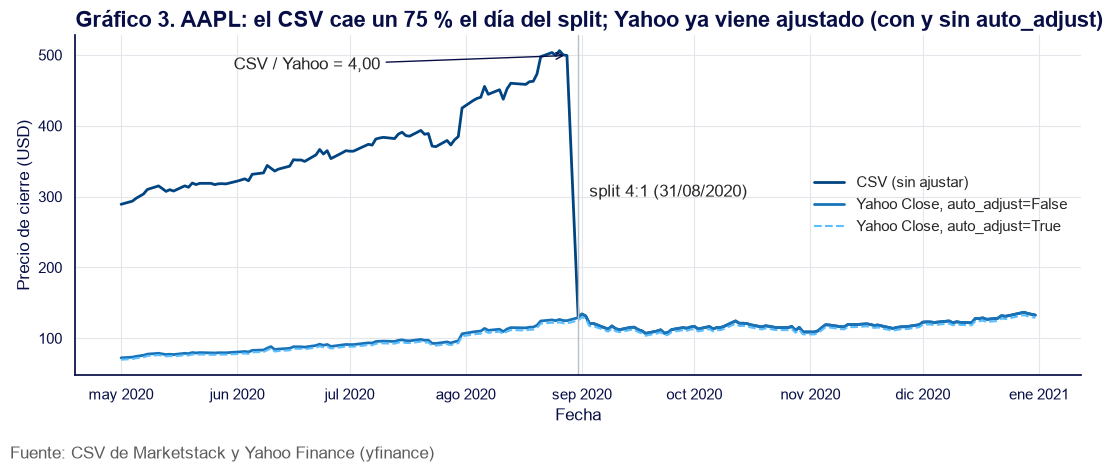

In [28]:
FECHA_SPLIT_AAPL = pd.Timestamp("2020-08-31")
aapl_csv = diario[diario["symbol"] == "AAPL"].set_index("date")["close"].loc["2020-05-01":"2020-12-31"]
aapl_yahoo = yahoo[yahoo["symbol"] == "AAPL"].set_index("date").loc["2020-05-01":"2020-12-31"]
aapl_sin_auto = aapl_yahoo["close"]
aapl_con_auto = aapl_yahoo["adj_close"]      # igual que Close con auto_adjust=True

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(aapl_csv, color=BBVA["principal"], lw=2, label="CSV (sin ajustar)")
ax.plot(aapl_sin_auto, color=BBVA["medio"], lw=2, label="Yahoo Close, auto_adjust=False")
ax.plot(aapl_con_auto, color=BBVA["cielo"], lw=1.5, ls="--", label="Yahoo Close, auto_adjust=True")
ax.axvline(FECHA_SPLIT_AAPL, color=BBVA["gris_dato"], lw=1)
ax.annotate("split 4:1 (31/08/2020)", xy=(FECHA_SPLIT_AAPL, 300), xytext=(8, 0), textcoords="offset points")
dia_antes = aapl_csv.loc[:FECHA_SPLIT_AAPL - pd.Timedelta(days=1)].index.max()
ax.annotate(f"CSV / Yahoo = {fmt_es(aapl_csv[dia_antes] / aapl_sin_auto[dia_antes], 2)}",
            xy=(dia_antes, aapl_csv[dia_antes]), xytext=(-240, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color=BBVA["marino"]))
ax.set_title("Gráfico 3. AAPL: el CSV cae un 75 % el día del split; Yahoo ya viene ajustado (con y sin auto_adjust)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de cierre (USD)")
numeros_es(ax.yaxis)
fechas_es(ax)
ax.legend(loc="center right")
plt.tight_layout()
anotar_fuente(fig, "CSV de Marketstack y Yahoo Finance (yfinance)")
guardar_mpl(fig, "limpieza_aapl_split_csv_vs_yahoo")
plt.show()

In [29]:
# Ajuste del CSV a la escala de Yahoo: precios / factor
# El volumen también se ajusta, pero no llega al dataset final: el volumen sale de Yahoo
diario["factor"] = [factor_split(t, f) for t, f in zip(diario["symbol"], diario["date"])]
for col in ["open", "high", "low", "close"]:
    diario[col] = diario[col] / diario["factor"]
diario["volume"] = diario["volume"] * diario["factor"]
print("\nFilas del CSV ajustadas:", int((diario["factor"] != 1).sum()))
print(diario.loc[diario["factor"] != 1].groupby("symbol")["factor"].agg(["min", "max", "count"]))
diario = diario.drop(columns=["factor"])


Filas del CSV ajustadas: 1374
          min    max  count
symbol                     
AAPL    4.000  4.000    581
IBM     1.046  1.046    271
MMM     1.196  1.196    271
MRK     1.048  1.048    251


# 9. Validación de la vela del CSV contra Yahoo 

In [30]:
validacion = diario.merge(yahoo[["symbol", "date", "open", "high", "low", "close"]], on=["symbol", "date"],
                          how="inner", suffixes=("", "_yahoo")).dropna(subset=["close"])
for col in ["open", "high", "low", "close"]:
    validacion[f"error_{col}"] = (validacion[col] / validacion[f"{col}_yahoo"] - 1) * 100


def resumen_error(e):
    e = e.abs()
    return pd.Series({"dias": len(e), "error_medio_%": round(e.mean(), 4), "mediana_%": round(e.median(), 4),
                      "max_%": round(e.max(), 3), "dias_>1%": int((e > 1).sum()), "dias_>5%": int((e > 5).sum())})


print("Error del cierre del CSV frente a Yahoo, según de dónde sale:")
print(validacion.groupby(np.where(validacion["incompleto"], "(día incompleto)", validacion["origen_close"]))["error_close"]
      .apply(resumen_error).unstack().to_string())

# Cierres con más del 1 % de error fuera de los días incompletos (se mantienen)
grandes = validacion[~validacion["incompleto"] & (validacion["error_close"].abs() > 1)]
print("\nCierres con más del 1 % de error:")
print(grandes[["symbol", "date", "origen_close", "close", "close_yahoo", "error_close"]].round({"close_yahoo": 3, "error_close": 3}).to_string(index=False))

Error del cierre del CSV frente a Yahoo, según de dónde sale:
                              dias  error_medio_%  mediana_%  max_%  dias_>1%  dias_>5%
(día incompleto)              50.0         0.5980     0.5452  1.730       9.0       0.0
close del día siguiente     6814.0         0.0000     0.0000  0.073       0.0       0.0
fila resumen                  43.0         0.0000     0.0000  0.000       0.0       0.0
último precio de la sesión  3104.0         0.0323     0.0126  4.537       6.0       0.0

Cierres con más del 1 % de error:
symbol       date               origen_close  close  close_yahoo  error_close
  AAPL 2020-03-18 último precio de la sesión  62.47       61.667        1.301
    GS 2020-06-11 último precio de la sesión 196.22      194.130        1.077
  INTC 2019-10-24 último precio de la sesión  54.33       52.230        4.021
  INTC 2020-01-23 último precio de la sesión  65.45       63.320        3.364
  INTC 2020-03-18 último precio de la sesión  49.77       47.610        4

El cierre oficial del CSV (close del día siguiente o fila resumen) coincide con Yahoo; el último precio de la sesión, el de los años antiguos, se desvía algo más porque IEX no recoge la subasta de cierre. Seis de esos cierres superan el 1 % (hasta el 4,5 %) y se mantienen: solo se descarta el cierre de los días incompletos.

# 10. Coherencia OHLC: high >= max(open, close) y low <= min(open, close)

In [31]:
def es_incoherente(d):
    return (d["high"] < d[["open", "close"]].max(axis=1)) | (d["low"] > d[["open", "close"]].min(axis=1))


def contar_incoherencias(d):
    d = d.dropna(subset=["close"])
    return int(es_incoherente(d).sum())


print("Velas incoherentes antes de reparar:", contar_incoherencias(diario), "de", diario["close"].notna().sum())
print(pd.crosstab(diario.loc[es_incoherente(diario), "origen_close"], diario.loc[es_incoherente(diario), "origen_ohl"]))

diario["high"] = diario[["high", "open", "close"]].max(axis=1)
diario["low"] = diario[["low", "open", "close"]].min(axis=1)
print("Velas incoherentes después de reparar:", contar_incoherencias(diario))

Velas incoherentes antes de reparar: 52 de 10125
origen_ohl               sesión
origen_close                   
close del día siguiente      52
Velas incoherentes después de reparar: 0


En esas velas el cierre oficial (subasta de cierre) cae fuera del high/low de la sesión, que solo recoge IEX: se amplía el rango en lugar de borrar la fila.

# 11. Combinación: el CSV manda, Yahoo imputa y da el volumen. Calendario = días de mercado de Yahoo

In [32]:
columnas = ["open", "high", "low", "close", "volume"]

# Filas del CSV en días sin mercado (festivos de la bolsa de EE. UU.)
festivos = diario.merge(calendario[["symbol", "date"]], on=["symbol", "date"], how="left", indicator=True)
festivos = festivos[festivos["_merge"] == "left_only"]
print("Filas del CSV en días sin mercado (se eliminan):", len(festivos), "| empresas:", sorted(festivos["symbol"].unique()))
print(festivos["date"].dt.strftime("%Y-%m-%d %a").value_counts().head(6).to_string())
precios_festivo = df.merge(festivos[["symbol", "date"]].rename(columns={"date": "dia_ny"}), on=["symbol", "dia_ny"])
print("Precios distintos dentro de cada festivo (máximo):",
      precios_festivo.groupby(["symbol", "dia_ny"])[["open", "high", "low", "close"]].nunique().max().max())
# Son barras planas con la bolsa cerrada: se eliminan para no meter retornos 0 falsos

# Días de mercado sin ninguna fila en el CSV dentro de su cobertura
cobertura = diario.groupby("symbol")["date"].agg(["min", "max"])
en_cobertura = calendario.merge(cobertura, left_on="symbol", right_index=True)
en_cobertura = en_cobertura[en_cobertura["date"].between(en_cobertura["min"], en_cobertura["max"])][["symbol", "date"]]
faltan = en_cobertura.merge(diario[["symbol", "date"]], how="left", indicator=True)
faltan = faltan[faltan["_merge"] == "left_only"]
print(f"\nDías de mercado sin ninguna fila en el CSV (dentro de su cobertura): {len(faltan)}")
print(faltan["date"].dt.date.value_counts().sort_index().to_string())

# Vale el CSV si tiene cierre y el día está completo; si no, los cuatro precios salen de Yahoo (sin mezclar fuentes)
# El volumen sale siempre de Yahoo: el del CSV solo es el total del mercado en la fila resumen; en el resto, solo IEX
precios_ohlc = ["open", "high", "low", "close"]
csv_valido = diario[diario["close"].notna() & ~diario["incompleto"]]
combinado = (
    calendario[["symbol", "date"]]
    .merge(csv_valido[["symbol", "date"] + precios_ohlc], on=["symbol", "date"], how="left")
    .merge(yahoo[["symbol", "date"] + columnas], on=["symbol", "date"], how="left", suffixes=("", "_yahoo"))
)
combinado["fuente"] = np.where(combinado["close"].notna(), "csv", "yahoo")
for col in precios_ohlc:
    combinado[col] = combinado[col].fillna(combinado[f"{col}_yahoo"])

df_final = (
    combinado[["symbol", "date"] + columnas + ["fuente"]]
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)

# Por qué toman los precios de Yahoo los días que caen dentro de la cobertura del CSV
motivo = en_cobertura.merge(df_final[["symbol", "date", "fuente"]], on=["symbol", "date"])
motivo = motivo[motivo["fuente"] == "yahoo"].merge(diario[["symbol", "date", "close", "incompleto"]], on=["symbol", "date"], how="left")
motivo["motivo"] = np.select([motivo["incompleto"].isna(), motivo["close"].isna()],
                             ["día sin filas en el CSV", "día sin cierre en el CSV"], "día incompleto en el CSV")
print("Filas imputadas desde Yahoo dentro de la cobertura del CSV:", motivo["motivo"].value_counts().to_dict())

Filas del CSV en días sin mercado (se eliminan): 114 | empresas: ['AAPL', 'CAT', 'GS', 'INTC', 'NKE', 'V']
date
2018-07-04 Wed    6
2018-09-03 Mon    6
2018-11-22 Thu    6
2018-12-05 Wed    6
2018-12-25 Tue    6
2019-01-01 Tue    6


Precios distintos dentro de cada festivo (máximo): 1

Días de mercado sin ninguna fila en el CSV (dentro de su cobertura): 58
date
2020-06-03    20
2020-06-10    22
2020-06-11     7
2020-06-12     9
Filas imputadas desde Yahoo dentro de la cobertura del CSV: {'día sin filas en el CSV': 58, 'día sin cierre en el CSV': 52, 'día incompleto en el CSV': 50}


# 12. Comprobaciones finales

Dimensiones del dataset final: (64557, 8)
Nulos totales: 0
Velas incoherentes: 0
Duplicados: 0

Distribución de fuentes:
        dias  dias_csv  pct_csv
symbol                         
AAPL    2514       768     30.5
AMGN    2514       269     10.7
AXP     2514       269     10.7
BA      2514       267     10.6
CAT     2514       766     30.5
CRM     2514       269     10.7
CSCO    2514       269     10.7
CVX     2514       269     10.7
DIS     2514       269     10.7
DOW     1707       269     15.8
GS      2514       767     30.5
HD      2514       267     10.6
IBM     2514       267     10.6
INTC    2514       768     30.5
JNJ     2514       269     10.7
JPM     2514       268     10.7
KO      2514       269     10.7
MCD     2514       269     10.7
MMM     2514       267     10.6
MRK     2514       267     10.6
MSFT    2514       267     10.6
NKE     2514       766     30.5
PG      2514       268     10.7
TRV     2514       266     10.6
UNH     2514       266     10.6
V       2514   

Guardado: Graficos\limpieza_aapl_dataset_final.png


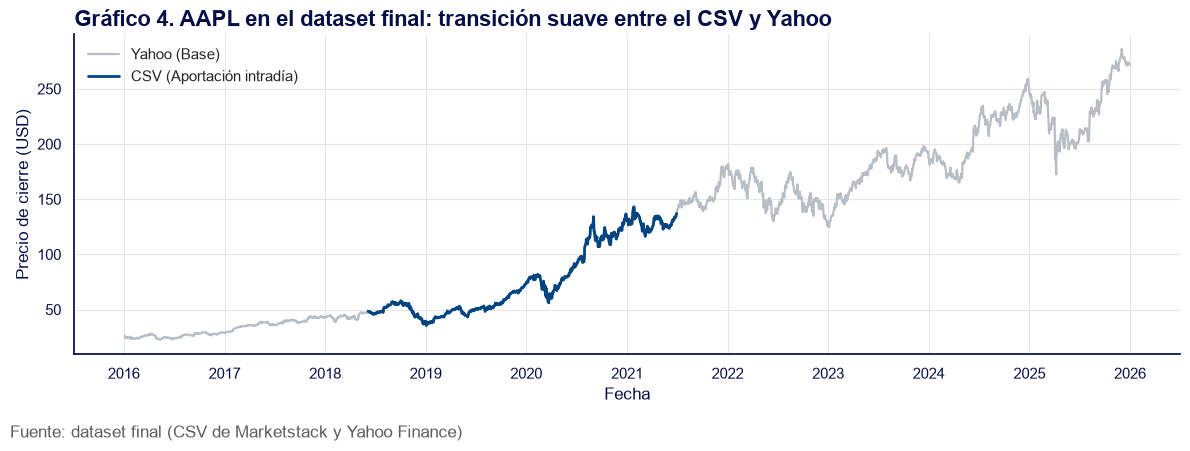

In [33]:
# 1. Resumen rápido de integridad
print(f"Dimensiones del dataset final: {df_final.shape}")
print(f"Nulos totales: {df_final[columnas].isna().sum().sum()}")
print(f"Velas incoherentes: {contar_incoherencias(df_final)}")
print(f"Duplicados: {df_final.duplicated(subset=['symbol', 'date']).sum()}")

# 2. Procedencia de los precios por empresa (el volumen sale siempre de Yahoo)
procedencia = df_final.groupby("symbol").agg(
    dias=("date", "size"),
    dias_csv=("fuente", lambda s: (s == "csv").sum()),
)
procedencia["pct_csv"] = (procedencia["dias_csv"] / procedencia["dias"] * 100).round(1)
print("\nDistribución de fuentes:")
print(procedencia.to_string())

# 3. Gráfico: AAPL 2016-2025 en el dataset final
aapl_final = df_final[df_final["symbol"] == "AAPL"].set_index("date")

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(aapl_final.index, aapl_final["close"], color=BBVA["gris_dato"], lw=1.6, label="Yahoo (Base)")
ax.plot(aapl_final.index, aapl_final["close"].where(aapl_final["fuente"] == "csv"), color=BBVA["principal"], lw=2, label="CSV (Aportación intradía)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de cierre (USD)")
numeros_es(ax.yaxis)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left")
ax.set_title("Gráfico 4. AAPL en el dataset final: transición suave entre el CSV y Yahoo")
plt.tight_layout()
anotar_fuente(fig, "dataset final (CSV de Marketstack y Yahoo Finance)")
guardar_mpl(fig, "limpieza_aapl_dataset_final")
plt.show()

# 13. Guardado (Datos/ no se sube al repositorio)

In [34]:
# Definir las columnas estrictamente necesarias
columnas_esenciales = ["symbol", "date", "open", "high", "low", "close", "volume"]
os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
df_final[columnas_esenciales].to_csv(f"{RUTA_TRANSFORMADOS}/dowjones_diario_2016_2025.csv", index=False)

print("Guardado limpio:", df_final[columnas_esenciales].shape)

Guardado limpio: (64557, 7)
